# Q1 - a


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms

use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)

train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 50)
        self.fc4 = nn.Linear(50, 10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

model = nn.Sequential(Normalize(), Net()).to(device)
model.train()

print("Device:", device)
print(model)


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.95MB/s]


Device: cuda
Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=50, bias=True)
    (fc2): Linear(in_features=50, out_features=50, bias=True)
    (fc3): Linear(in_features=50, out_features=50, bias=True)
    (fc4): Linear(in_features=50, out_features=10, bias=True)
  )
)


In [ ]:

def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    start = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

    if use_cuda:
        torch.cuda.synchronize()
    return time.time() - start

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0

        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    acc = 100 * correct / total
    print(f'Accuracy on images: {acc:.2f}%')
    return acc


In [ ]:

def ibp_bounds(model, images, eps):
    images = images.view(-1, 784)

    low = (images - eps).clamp(0, 1)
    high = (images + eps).clamp(0, 1)

    low = (low - 0.1307) / 0.3081
    high = (high - 0.1307) / 0.3081

    center = (low + high) / 2
    radius = (high - low) / 2

    layers = [model[1].fc, model[1].fc2, model[1].fc3, model[1].fc4]

    for i, layer in enumerate(layers):
        center_new = F.linear(center, layer.weight, layer.bias)
        radius_new = F.linear(radius, layer.weight.abs())

        low = center_new - radius_new
        high = center_new + radius_new

        if i < 3:
            low = F.relu(low)
            high = F.relu(high)

        center = (low + high) / 2
        radius = (high - low) / 2

    return low, high


In [ ]:

def ibp_loss(model, images, labels, eps, k):
    out = model(images)
    loss = F.cross_entropy(out, labels)

    low, high = ibp_bounds(model, images, eps)
    z = high.clone()
    idx = torch.arange(len(labels), device=device)
    z[idx, labels] = low[idx, labels]

    ibp = F.cross_entropy(z, labels)
    return k * loss + (1 - k) * ibp


In [ ]:

def train_ibp(model, num_epochs):
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
    start = time.time()

    for epoch in range(num_epochs):
        model.train()
        loss_sum = 0

        p = epoch / (num_epochs - 1)
        k = 1 - 0.5 * p
        eps = 0.1 * p

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            loss = ibp_loss(model, images, labels, eps, k)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss_sum/len(train_loader):.3f}, k: {k:.3f}, eps: {eps:.3f}')

    if use_cuda:
        torch.cuda.synchronize()
    return time.time() - start


In [ ]:

def clip_box(x, delta):
    return (x + delta).clamp(0, 1) - x

def input_grad(model, x, delta, y):
    delta = delta.detach().requires_grad_(True)
    loss = F.cross_entropy(model(x + delta), y, reduction="sum")
    (grad,) = torch.autograd.grad(loss, delta)
    return grad.detach()

def pgd_linf(model, x, y, eps, alpha, steps, rand_init=True):
    delta = torch.zeros_like(x)
    if rand_init:
        delta = torch.empty_like(x).uniform_(-eps, eps)
        delta = clip_box(x, delta)

    for _ in range(steps):
        grad = input_grad(model, x, delta, y)
        delta = delta + alpha * grad.sign()
        delta = delta.clamp(-eps, eps)
        delta = clip_box(x, delta)

    return (x + delta).detach()

def pgd_acc(model, eps=0.1):
    model.eval()
    correct = 0
    total = 0

    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        adv = pgd_linf(model, x, y, eps, 0.01, 20)

        with torch.no_grad():
            pred = model(adv).argmax(1)
            correct += (pred == y).sum().item()

        total += len(y)

    acc = 100 * correct / total
    print(f'PGD Accuracy: {acc:.2f}%')
    return acc


In [ ]:

import copy

base = nn.Sequential(Normalize(), Net()).to(device)
std_model = copy.deepcopy(base)
ibp_model = copy.deepcopy(base)
std_time = train_model(std_model, 15)
ibp_time = train_ibp(ibp_model, 15)
std_acc = test_model(std_model)
std_pgd = pgd_acc(std_model)
ibp_acc = test_model(ibp_model)
ibp_pgd = pgd_acc(ibp_model)

print("Standard:", std_acc, std_pgd, std_time)
print("IBP:", ibp_acc, ibp_pgd, ibp_time)


Epoch 1/15, Loss: 1.265
Epoch 2/15, Loss: 0.365
Epoch 3/15, Loss: 0.288
Epoch 4/15, Loss: 0.241
Epoch 5/15, Loss: 0.207
Epoch 6/15, Loss: 0.180
Epoch 7/15, Loss: 0.160
Epoch 8/15, Loss: 0.144
Epoch 9/15, Loss: 0.132
Epoch 10/15, Loss: 0.121
Epoch 11/15, Loss: 0.112
Epoch 12/15, Loss: 0.103
Epoch 13/15, Loss: 0.096
Epoch 14/15, Loss: 0.091
Epoch 15/15, Loss: 0.085
Epoch 1/15, Loss: 1.265, k: 1.000, eps: 0.000
Epoch 2/15, Loss: 0.590, k: 0.964, eps: 0.007
Epoch 3/15, Loss: 0.589, k: 0.929, eps: 0.014
Epoch 4/15, Loss: 0.558, k: 0.893, eps: 0.021
Epoch 5/15, Loss: 0.546, k: 0.857, eps: 0.029
Epoch 6/15, Loss: 0.557, k: 0.821, eps: 0.036
Epoch 7/15, Loss: 0.576, k: 0.786, eps: 0.043
Epoch 8/15, Loss: 0.599, k: 0.750, eps: 0.050
Epoch 9/15, Loss: 0.624, k: 0.714, eps: 0.057
Epoch 10/15, Loss: 0.656, k: 0.679, eps: 0.064
Epoch 11/15, Loss: 0.694, k: 0.643, eps: 0.071
Epoch 12/15, Loss: 0.735, k: 0.607, eps: 0.079
Epoch 13/15, Loss: 0.779, k: 0.571, eps: 0.086
Epoch 14/15, Loss: 0.830, k: 0.5

# Q1 - b

In [ ]:

def verified_acc(epsilon):
    ibp_model.eval()
    verified = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            low, high = ibp_bounds(ibp_model, images, epsilon)

            idx = torch.arange(len(labels), device=device)
            true_low = low[idx, labels]
            high[idx, labels] = float("-inf")

            verified += (true_low[:, None] > high).all(dim=1).sum().item()
            total += len(labels)

    return 100 * verified / total


In [ ]:

epsilons = np.linspace(0.01, 0.10, 10)
results = []

for epsilon in epsilons:
    acc = verified_acc(float(epsilon))
    results.append(acc)
    print("Epsilon:", round(epsilon, 2), "Verified:", round(acc, 2))


Epsilon: 0.01 Verified: 90.13
Epsilon: 0.02 Verified: 88.24
Epsilon: 0.03 Verified: 86.42
Epsilon: 0.04 Verified: 84.25
Epsilon: 0.05 Verified: 82.09
Epsilon: 0.06 Verified: 79.28
Epsilon: 0.07 Verified: 76.06
Epsilon: 0.08 Verified: 72.82
Epsilon: 0.09 Verified: 68.83
Epsilon: 0.1 Verified: 63.98


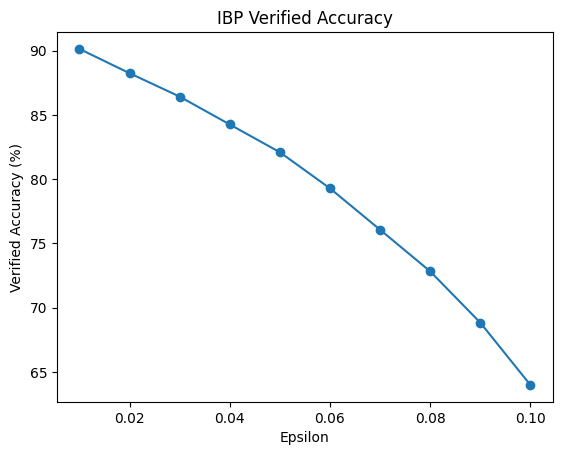

In [ ]:

plt.plot(epsilons, results, marker="o")
plt.xlabel("Epsilon")
plt.ylabel("Verified Accuracy (%)")
plt.title("IBP Verified Accuracy")
plt.show()


In [ ]:

eps = 0.1
examples = []

ibp_model.eval()

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    with torch.no_grad():
        low, high = ibp_bounds(ibp_model, images, eps)
        idx = torch.arange(len(labels), device=device)
        true_low = low[idx, labels]
        high[idx, labels] = float("-inf")
        failed = ~(true_low[:, None] > high).all(dim=1)
        correct = ibp_model(images).argmax(1) == labels

    mask = failed & correct
    if not mask.any():
        continue

    x = images[mask]
    y = labels[mask]
    adv = pgd_linf(ibp_model, x, y, eps, 0.01, 20)

    with torch.no_grad():
        pred = ibp_model(adv).argmax(1)

    for i in range(len(y)):
        if pred[i] != y[i]:
            examples.append((x[i].cpu(), adv[i].cpu(), y[i].item(), pred[i].item()))
        if len(examples) >= 5:
            break

    if len(examples) >= 5:
        break

print("Adversarial examples found:", len(examples))


Adversarial examples found: 5


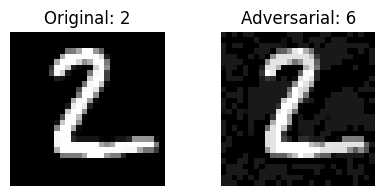

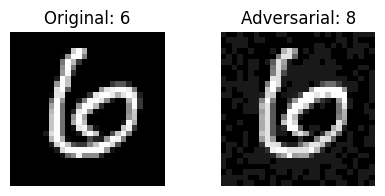

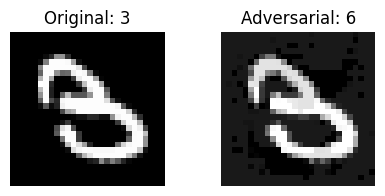

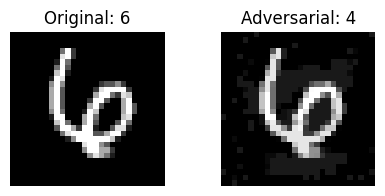

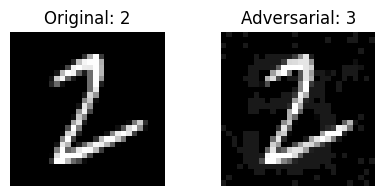

In [ ]:

for i, (x, adv, y, pred) in enumerate(examples):
    plt.figure(figsize=(5, 2))

    plt.subplot(1, 2, 1)
    plt.imshow(x.squeeze(), cmap="gray")
    plt.title("Original: " + str(y))
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(adv.squeeze(), cmap="gray")
    plt.title("Adversarial: " + str(pred))
    plt.axis("off")

    plt.show()
